# Predicción de riesgo: comparación de cuatro modelos

**Objetivo:** predecir `Risk_Level` de un proyecto al ingresar, usando las 13 variables candidatas del formulario. Comparamos regresión logística, árbol de decisión, Random Forest y CatBoost.

**Protocolo:** 80% para desarrollo con validación cruzada estratificada de 3 folds; 20% de test reservado. Elegimos por macro-F1 medio en validación; desempatamos por recall de High/Critical y menor tiempo de búsqueda. El test se abre después de fijar el ganador. No seleccionamos el modelo por su resultado en test.

**Límite:** los campos deben corresponder al día 1; esto no está confirmado. El CSV completo ya fue explorado, por lo que el test es una evaluación interna aproximada, no una validación externa. No hay fechas completas ni clientes para separar por tiempo o cliente.

Ejecutar en orden junto a `project_dataset.csv`. En VS Code, seleccionar `.venv_modelos/Scripts/python.exe` como kernel. En otro entorno, instalar las versiones de `requirements_modelos.txt`. Las salidas ya están guardadas.

## 1. Datos y variables
Cinco cantidades numéricas y ocho listas categóricas. Conservamos `None` y `N/A` como texto. El identificador no se usa para predecir y el objetivo no entra en X.

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (make_scorer, f1_score, recall_score, precision_score,
    accuracy_score, classification_report, ConfusionMatrixDisplay)
from catboost import CatBoostClassifier

SEED = 42
CLASES = ['Low', 'Medium', 'High', 'Critical']
NUM = ['Project_Budget_USD', 'Estimated_Timeline_Months', 'Team_Size',
       'Stakeholder_Count', 'External_Dependencies_Count']
CAT = ['Project_Type', 'Team_Experience_Level', 'Technology_Familiarity',
       'Requirement_Stability', 'Executive_Sponsorship', 'Key_Stakeholder_Availability',
       'Org_Process_Maturity', 'Risk_Management_Maturity']
FEATURES = NUM + CAT
ruta = Path('project_dataset.csv')
df = pd.read_csv(ruta, keep_default_na=False)
X, y = df[FEATURES].copy(), df['Risk_Level'].copy()
assert set(y.unique()) == set(CLASES)
assert not X.isna().any().any() and not X.astype(str).eq('').any().any()
for c in CAT:
    X[c] = X[c].astype(str)
for c in NUM:
    X[c] = pd.to_numeric(X[c], errors='raise')
pd.set_option('display.max_colwidth', 95)
pd.set_option('display.float_format', lambda v: f'{v:.3f}')
plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'{len(X):,} proyectos | {len(NUM)} variables numéricas + {len(CAT)} categóricas')
print('SHA-256 del CSV:', hashlib.sha256(ruta.read_bytes()).hexdigest())
print({p: metadata.version(p) for p in ['pandas', 'numpy', 'scikit-learn', 'catboost']})
display(pd.DataFrame({'grupo': ['Numéricas', 'Categóricas'],
                      'columnas': [', '.join(NUM), ', '.join(CAT)]}))

4,000 proyectos | 5 variables numéricas + 8 categóricas
SHA-256 del CSV: 645c600b1a89b126341ec2c84ea0347580937d71df9727efd04a3a007ec0ede7
{'pandas': '3.0.1', 'numpy': '2.3.5', 'scikit-learn': '1.9.1', 'catboost': '1.2.10'}


,grupo,columnas
0,Numéricas,"Project_Budget_USD, Estimated_Timeline_Months, Team_Size, Stakeholder_Count, External_Depen..."
1,Categóricas,"Project_Type, Team_Experience_Level, Technology_Familiarity, Requirement_Stability, Executi..."


## 2. Separación antes de transformar
Se reservan **800 proyectos para test**. Las búsquedas solo usan los **3.200 de desarrollo**, con los mismos tres folds para todos. Estratificar mantiene aproximadamente la proporción de clases. Cada fold vuelve a ajustar las transformaciones exclusivamente con su parte de entrenamiento.

In [2]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=.20, stratify=y, random_state=SEED)
assert set(X_dev.index).isdisjoint(X_test.index)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
folds = list(cv.split(X_dev, y_dev))
display(pd.DataFrame({'desarrollo': y_dev.value_counts(),
                      'test reservado': y_test.value_counts()}).reindex(CLASES))
print(f'Desarrollo: {len(X_dev)} | Test: {len(X_test)}')

,desarrollo,test reservado
Risk_Level,,
Low,645,161
Medium,1117,279
High,829,207
Critical,609,153


Desarrollo: 3200 | Test: 800


## 3. Transformación y modelos

| Modelo | Categorías | Números | Parámetros comparados |
|---|---|---|---|
| Regresión logística | One-hot | Mediana + estandarización | Regularización C: 0,1 y 1 |
| Árbol | One-hot | Mediana, sin escalar | Profundidad 3/6; mínimo por hoja 20/50 |
| Random Forest | One-hot | Mediana, sin escalar | Profundidad 8/sin límite; 250 árboles, mínimo por hoja 5 |
| CatBoost | Manejo interno de categorías | Escala original | Profundidad 4/6; 350 iteraciones |

Es una búsqueda pequeña para mantener el ejercicio simple, no una optimización exhaustiva. No generamos muestras sintéticas. Los imputadores permiten faltantes numéricos técnicamente, pero no prueban robustez ante su ausencia futura: el archivo actual no tiene vacíos y los campos esenciales deben validarse en el formulario. Para CatBoost no hacemos one-hot externo.

Las métricas de High/Critical agrupan **las clases predichas** High y Critical; no usamos un umbral probabilístico adicional. Macro-F1 da el mismo peso a las cuatro clases. Recall elevado mide qué proporción de High/Critical reales detectamos; precisión elevada mide cuántas alertas de ese grupo son correctas.

In [3]:
def preprocesador(escalar=False):
    pasos = [('imputar', SimpleImputer(strategy='median'))]
    if escalar:
        pasos.append(('escalar', StandardScaler()))
    return ColumnTransformer([
        ('numeros', Pipeline(pasos), NUM),
        ('categorias', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT)
    ])

def recall_elevado(y_real, y_pred):
    return recall_score(np.isin(np.asarray(y_real).ravel(), ['High', 'Critical']),
                        np.isin(np.asarray(y_pred).ravel(), ['High', 'Critical']), zero_division=0)

scoring = {'f1_macro': 'f1_macro', 'accuracy': 'accuracy',
           'recall_elevado': make_scorer(recall_elevado)}
configuraciones = {
    'Regresión logística': (
        Pipeline([('preparar', preprocesador(True)),
                  ('modelo', LogisticRegression(max_iter=2000, random_state=SEED))]),
        {'modelo__C': [.1, 1]}),
    'Árbol de decisión': (
        Pipeline([('preparar', preprocesador()),
                  ('modelo', DecisionTreeClassifier(random_state=SEED))]),
        {'modelo__max_depth': [3, 6], 'modelo__min_samples_leaf': [20, 50]}),
    'Random Forest': (
        Pipeline([('preparar', preprocesador()),
                  ('modelo', RandomForestClassifier(n_estimators=250, min_samples_leaf=5,
                                                    random_state=SEED, n_jobs=4))]),
        {'modelo__max_depth': [8, None]}),
    'CatBoost': (
        CatBoostClassifier(iterations=350, learning_rate=.05, loss_function='MultiClass',
            cat_features=tuple(CAT), random_seed=SEED, verbose=False, allow_writing_files=False,
            thread_count=4),
        {'depth': [4, 6]})
}

## 4. Entrenamiento, validación y elección
Cada búsqueda elige sus parámetros por macro-F1. Después comparamos los cuatro candidatos con ese mismo criterio. La desviación entre folds ayuda a ver variación; no es un intervalo de confianza ni una prueba de superioridad estadística. El tiempo incluye todos los ajustes y el reentrenamiento final de cada búsqueda, por lo que también depende del tamaño de la grilla y del equipo.

Regresión logística: búsqueda terminada (0.6 s)
Árbol de decisión: búsqueda terminada (0.5 s)
Random Forest: búsqueda terminada (3.6 s)
CatBoost: búsqueda terminada (53.2 s)


,F1 macro CV,desv. F1 CV,recall High/Critical CV,accuracy CV,segundos búsqueda,mejores parámetros
modelo,,,,,,
Regresión logística,0.539,0.006,0.699,0.540,0.570,{'modelo__C': 1}
CatBoost,0.530,0.004,0.677,0.531,53.183,{'depth': 4}
Random Forest,0.491,0.005,0.618,0.502,3.595,{'modelo__max_depth': None}
Árbol de decisión,0.423,0.021,0.595,0.443,0.483,"{'modelo__max_depth': 6, 'modelo__min_samples_leaf': 20}"


**Candidato elegido por validación: Regresión logística.**

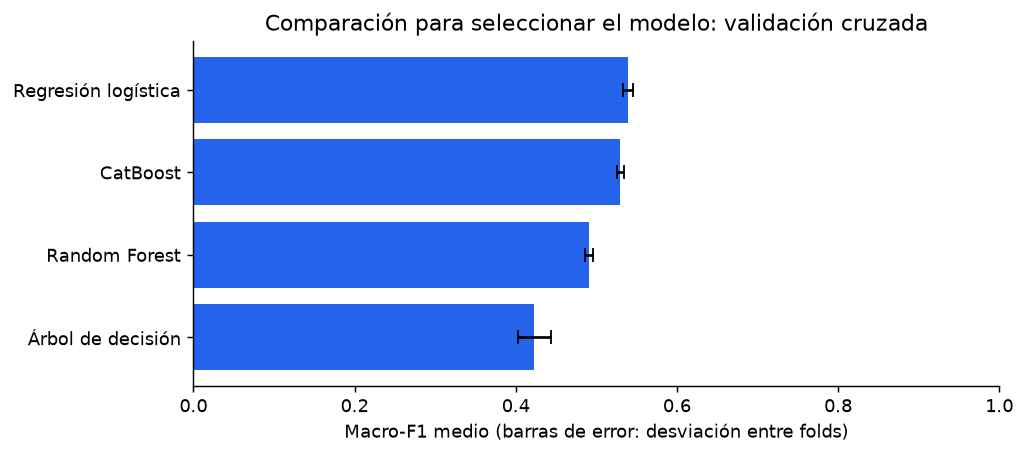

In [4]:
busquedas, filas_cv = {}, []
for nombre, (estimador, parametros) in configuraciones.items():
    inicio = perf_counter()
    busqueda = GridSearchCV(estimador, parametros, scoring=scoring, refit='f1_macro',
                           cv=folds, n_jobs=1, error_score='raise', return_train_score=False)
    busqueda.fit(X_dev, y_dev)
    segundos = perf_counter() - inicio
    busquedas[nombre] = busqueda
    i, r = busqueda.best_index_, busqueda.cv_results_
    filas_cv.append({'modelo': nombre, 'F1 macro CV': r['mean_test_f1_macro'][i],
        'desv. F1 CV': r['std_test_f1_macro'][i],
        'recall High/Critical CV': r['mean_test_recall_elevado'][i],
        'accuracy CV': r['mean_test_accuracy'][i], 'segundos búsqueda': segundos,
        'mejores parámetros': busqueda.best_params_})
    print(f'{nombre}: búsqueda terminada ({segundos:.1f} s)')

comparacion_cv = pd.DataFrame(filas_cv).set_index('modelo').sort_values(
    ['F1 macro CV', 'recall High/Critical CV', 'segundos búsqueda'], ascending=[False, False, True])
elegido = comparacion_cv.index[0]  # Se fija ANTES de evaluar el test.
display(comparacion_cv)
display(Markdown(f'**Candidato elegido por validación: {elegido}.**'))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(comparacion_cv.index, comparacion_cv['F1 macro CV'],
        xerr=comparacion_cv['desv. F1 CV'], color='#2563eb', capsize=4)
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel='Macro-F1 medio (barras de error: desviación entre folds)',
       title='Comparación para seleccionar el modelo: validación cruzada')
fig.tight_layout()
plt.show()

## 5. Test reservado: comparación descriptiva
Los mejores estimadores ya están reentrenados con los 3.200 proyectos de desarrollo. Se evalúan ahora en los mismos 800 de test, sin reajustarlos. Mostramos los cuatro resultados para comparar, **sin cambiar el ganador elegido en validación**. Incluimos una referencia que siempre predice la clase mayoritaria.

Accuracy por sí sola no basta: podemos acertar la clase más frecuente y omitir riesgos elevados. Si se cambian variables o parámetros después de ver esta tabla, este test deja de ser una prueba final independiente.

,accuracy,F1 macro,recall High/Critical,precisión High/Critical,recall Critical,High/Critical omitidos,ms por lote de test,elegido en CV
modelo,,,,,,,,
Regresión logística,0.519,0.518,0.706,0.789,0.549,106,7.600,True
Árbol de decisión,0.446,0.416,0.500,0.741,0.405,180,5.165,False
Random Forest,0.470,0.459,0.606,0.773,0.464,142,61.815,False
CatBoost,0.484,0.474,0.672,0.786,0.477,118,5.067,False
Referencia: siempre Medium,0.349,0.129,0.000,0.000,0.000,360,NaN,False


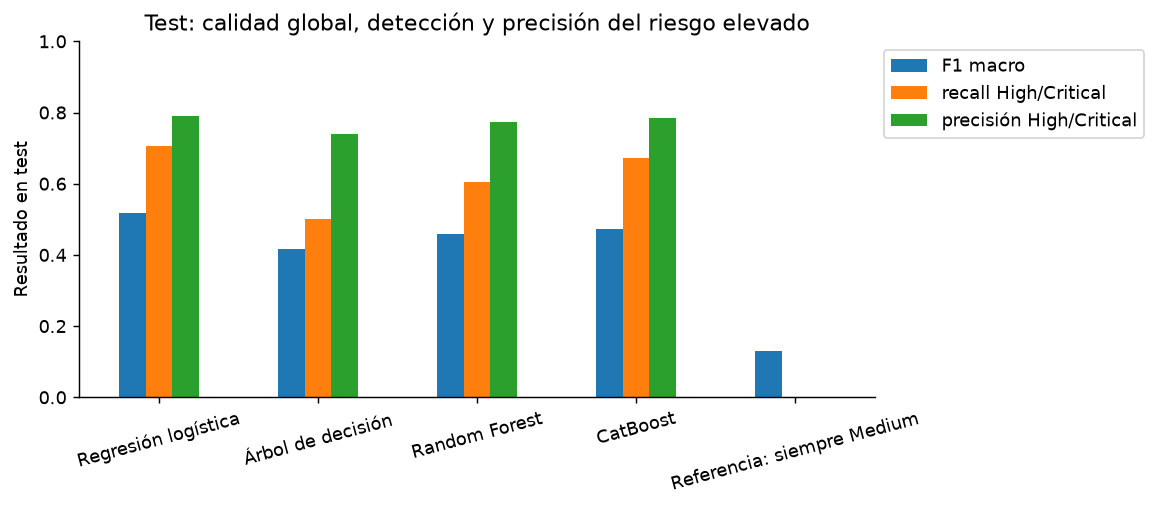

In [5]:
def metricas(y_real, pred):
    pred = np.asarray(pred).ravel()
    real_alto = np.isin(np.asarray(y_real), ['High', 'Critical'])
    pred_alto = np.isin(pred, ['High', 'Critical'])
    return {'accuracy': accuracy_score(y_real, pred),
            'F1 macro': f1_score(y_real, pred, average='macro', zero_division=0),
            'recall High/Critical': recall_score(real_alto, pred_alto, zero_division=0),
            'precisión High/Critical': precision_score(real_alto, pred_alto, zero_division=0),
            'recall Critical': recall_score(y_real, pred, labels=['Critical'], average='macro', zero_division=0),
            'High/Critical omitidos': int((real_alto & ~pred_alto).sum())}

predicciones, filas_test = {}, []
for nombre, busqueda in busquedas.items():
    inicio = perf_counter()
    pred = np.asarray(busqueda.best_estimator_.predict(X_test)).ravel()
    milisegundos = (perf_counter() - inicio) * 1000
    predicciones[nombre] = pred
    filas_test.append({'modelo': nombre, **metricas(y_test, pred),
                       'ms por lote de test': milisegundos})
base = DummyClassifier(strategy='most_frequent').fit(X_dev, y_dev)
filas_test.append({'modelo': 'Referencia: siempre Medium',
                   **metricas(y_test, base.predict(X_test)), 'ms por lote de test': np.nan})
comparacion_test = pd.DataFrame(filas_test).set_index('modelo')
comparacion_test['elegido en CV'] = comparacion_test.index == elegido
display(comparacion_test)

fig, ax = plt.subplots(figsize=(9, 4))
comparacion_test[['F1 macro', 'recall High/Critical', 'precisión High/Critical']].plot.bar(ax=ax)
ax.set(ylim=(0, 1), ylabel='Resultado en test', xlabel='',
       title='Test: calidad global, detección y precisión del riesgo elevado')
ax.tick_params(axis='x', rotation=15)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
fig.tight_layout()
plt.show()

## 6. Errores y conclusión
Las matrices muestran el porcentaje por clase real. La diagonal es acierto; las celdas High/Critical predichas como Low/Medium son omisiones relevantes. El reporte del elegido conserva los conteos de soporte. Esta evaluación no demuestra que una acción de atención reduzca incidentes, ni que las probabilidades estén calibradas.

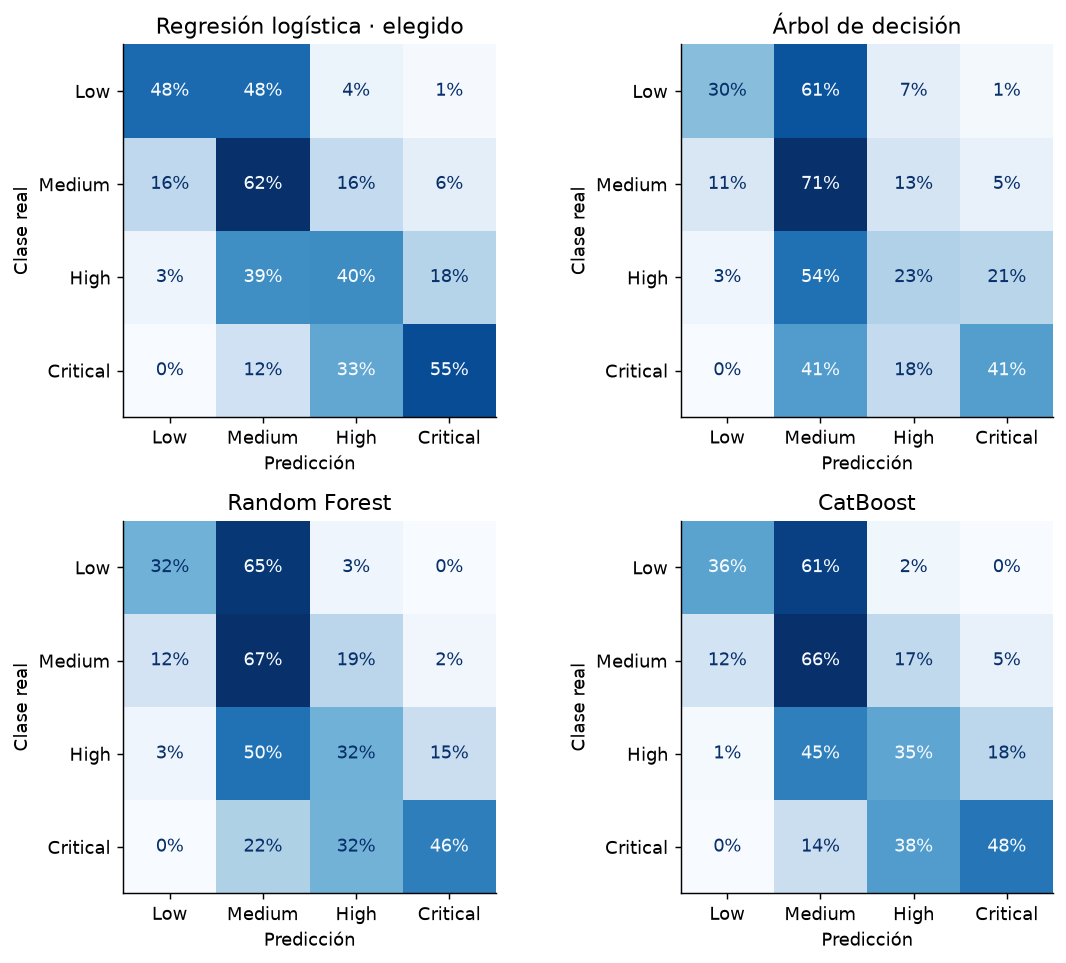

,precision,recall,f1-score,support
Low,0.597,0.478,0.531,161.000
Medium,0.493,0.616,0.548,279.000
High,0.451,0.396,0.422,207.000
Critical,0.600,0.549,0.573,153.000
accuracy,0.519,0.519,0.519,0.519
macro avg,0.535,0.510,0.518,800.000
weighted avg,0.523,0.519,0.517,800.000


**Elección: Regresión logística**, por el mayor macro-F1 medio de validación (0.539). En test obtuvo macro-F1 **0.518**, recall de High/Critical **70.6%** y omitió **106** proyectos de ese grupo. La elección es provisional: comparar errores, carga operativa y definiciones de los campos antes de integrarlo al formulario.

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7.5))
for ax, (nombre, pred) in zip(axes.ravel(), predicciones.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=CLASES,
        normalize='true', display_labels=CLASES, ax=ax, cmap='Blues',
        colorbar=False, values_format='.0%')
    ax.set_title(nombre + (' · elegido' if nombre == elegido else ''))
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Clase real')
fig.tight_layout()
plt.show()

reporte = classification_report(y_test, predicciones[elegido], labels=CLASES,
                                 output_dict=True, zero_division=0)
display(pd.DataFrame(reporte).T)
resultado = comparacion_test.loc[elegido]
display(Markdown(
    f'**Elección: {elegido}**, por el mayor macro-F1 medio de validación '
    f'({comparacion_cv.loc[elegido, "F1 macro CV"]:.3f}). '
    f'En test obtuvo macro-F1 **{resultado["F1 macro"]:.3f}**, '
    f'recall de High/Critical **{resultado["recall High/Critical"]:.1%}** '
    f'y omitió **{int(resultado["High/Critical omitidos"])}** proyectos de ese grupo. '
    'La elección es provisional: comparar errores, carga operativa y definiciones de los campos antes de integrarlo al formulario.'))

# Los resultados y las particiones quedan disponibles para reproducir la comparación.
salidas = Path('resultados_modelos')
salidas.mkdir(exist_ok=True)
comparacion_cv.to_csv(salidas / 'comparacion_validacion.csv', encoding='utf-8-sig')
comparacion_test.to_csv(salidas / 'comparacion_test.csv', encoding='utf-8-sig')
pd.DataFrame({'Project_ID': df.Project_ID, 'partición':
    np.where(df.index.isin(X_test.index), 'test', 'desarrollo')}).to_csv(
    salidas / 'particiones.csv', index=False, encoding='utf-8-sig')

**Siguiente paso:** revisar los errores del modelo elegido y conectar sus 13 entradas y su preprocesamiento con el formulario. Las reglas que convierten el riesgo en acciones se mantienen separadas del clasificador. No se cambia el candidato por mirar el test.

Referencias: [pipelines con datos mixtos](https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html), [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html), [CatBoostClassifier](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier).

Rastro de IA: asistencia para definir particiones, grillas pequeñas, transformaciones, métricas y código. Los resultados provienen de la ejecución del notebook; no son valores simulados.